# Transformada de Laplace


In [10]:
import numpy
import sympy
import matplotlib.pyplot as plt
#sympy.init_printing()

In [11]:
t, s = sympy.symbols('t, s')
a = sympy.symbols('a', real=True, positive=True)

In [12]:
a = 2
f = sympy.exp(-a*t)
f

exp(-2*t)

Text(0, 0.5, '$\\exp(-2t)$ [m]')

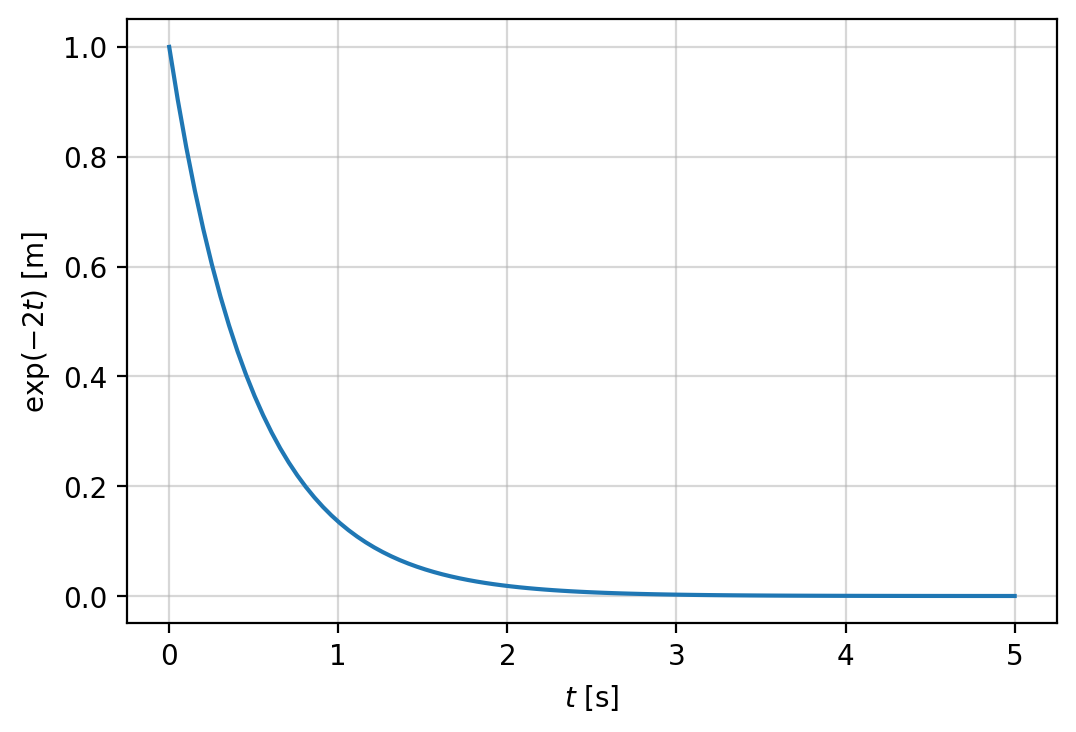

In [13]:
f_num = sympy.lambdify(t, f) 
tt = numpy.linspace(0,5,100)
plt.figure(dpi=200)
plt.plot(tt,f_num(tt))
plt.grid(alpha=0.5)
plt.xlabel("$t$ [s]")
plt.ylabel("$\exp(-2t)$ [m]")

In [14]:

F = sympy.laplace_transform(f, t, s, noconds=True)
F

1/(s + 2)

In [15]:
f = sympy.inverse_laplace_transform(F, s, t)
f

exp(-2*t)*Heaviside(t)

In [16]:
F_num = sympy.lambdify(s, F) 

In [17]:
sigma = numpy.linspace(-14,6,100)
omega = numpy.linspace(-10,10,100)
Sigma, Omega = numpy.meshgrid(sigma, omega)
Z = F_num( Sigma + 1j*Omega)
Z = numpy.abs(Z)
Z[Z>1] = 1

Text(0.5, 0, '$ \\omega $ [rad/s]')

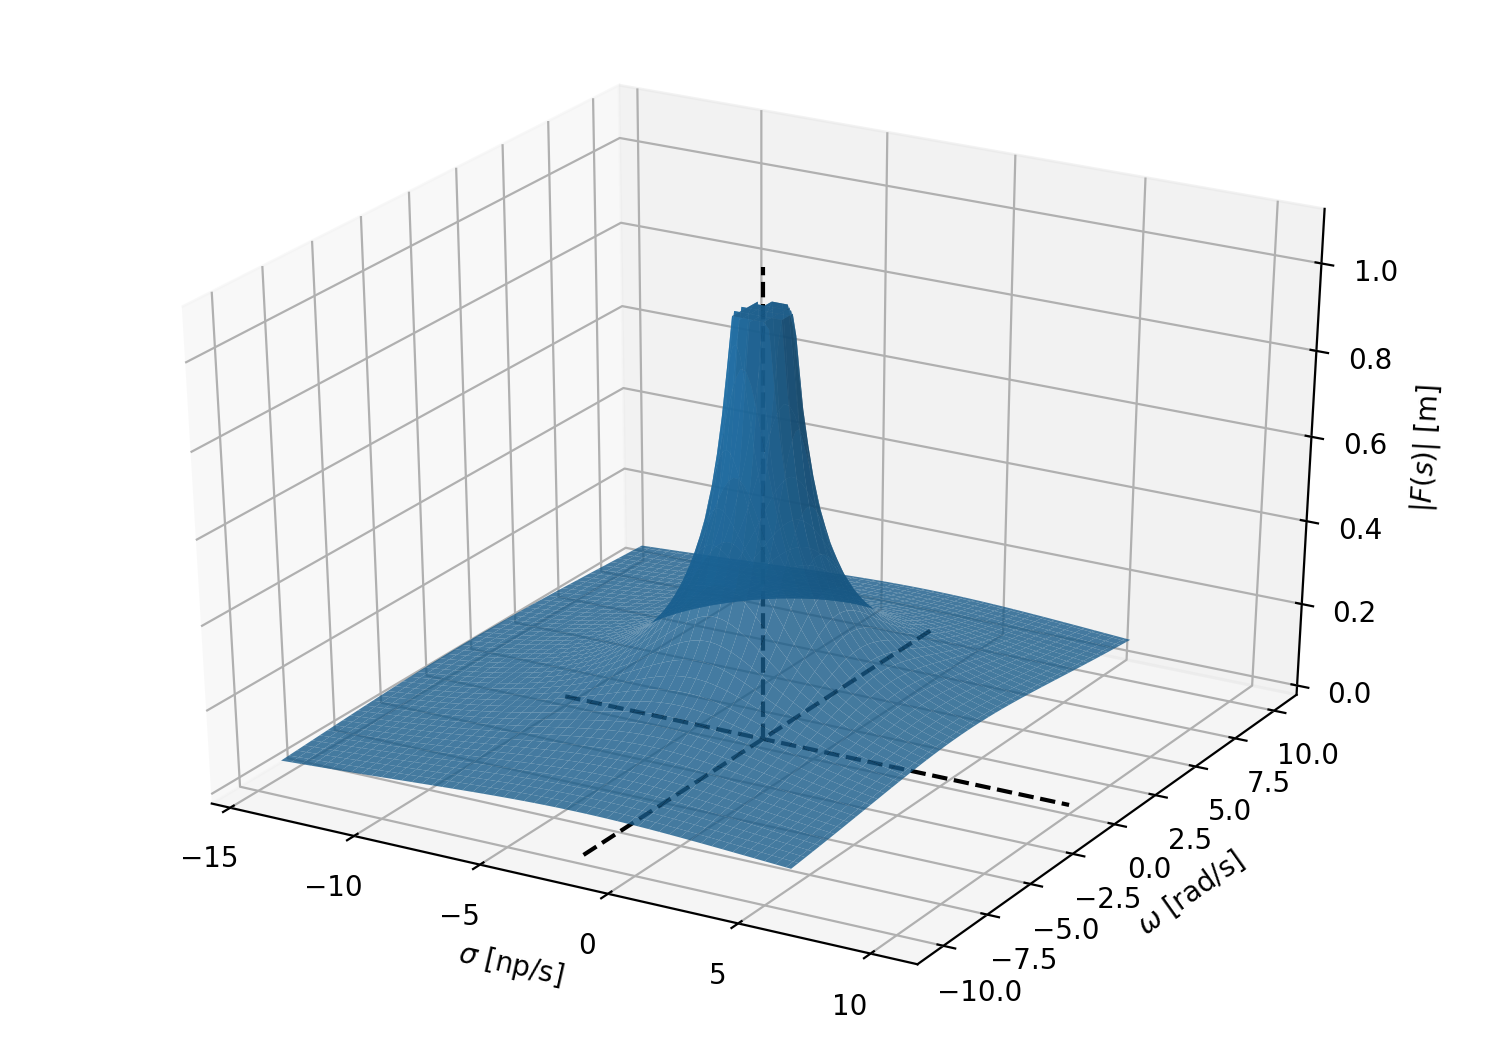

In [18]:
fig = plt.figure(dpi=200,figsize=(14/1.5,10/1.5))
ax = plt.axes(projection="3d")
ax.plot_surface(Sigma,Omega,Z, alpha=0.8)
ax.plot([-a,-a] ,[-10,10], color='k', ls='--')
ax.plot([-10,10] ,[0,0], color='k', ls='--')
ax.plot ([-a,-a] ,[0,0],[0,1.1], color='k', ls='--')
ax.set_zlabel("$| {F( s )} |$ [m]")
ax.set_xlabel("$ \sigma $ [np/s]")
ax.set_ylabel("$ \omega $ [rad/s]")
